# Sinkhorn Autoencoder for 3D Point Clouds (ModelNet40)

**Author's note for future-me:** This notebook is fully self-contained. Every code cell
is preceded by a markdown cell that explains *why* the cell exists, *what* mathematical
object it computes, and *how* it fits into the overall pipeline. If you're reading this
100 days from now, you should be able to re-derive the whole thing from the notebook alone.

---

## The Problem

We want an autoencoder whose input is a **3D point cloud** — an unordered set of `N`
points in ℝ³, written as a matrix `X ∈ ℝ^{N×3}`. We want:

1. A **latent code** `z ∈ ℝ^d` that summarizes the shape.
2. A **decoder** that maps `z` back to a point cloud `X̂ ∈ ℝ^{N×3}` close to the input.
3. The encoder must be **permutation-invariant**: `Enc(πX) = Enc(X)` for any permutation π.

## Why Standard Losses Fail

The naive reconstruction loss is MSE:
$$
\mathcal{L}_{\text{MSE}}(X, \hat{X}) = \frac{1}{N}\sum_{i=1}^{N} \|x_i - \hat{x}_i\|^2
$$
This is **mathematically invalid for sets** because it assumes a fixed correspondence
between input and output points. Shuffle the output points and MSE explodes even though
the *set* is identical.

## The Pipeline

$$
X \in \mathbb{R}^{N\times 3}
\;\xrightarrow{\text{Encoder}}\;
(\mu, \log\sigma^2) \in \mathbb{R}^d \times \mathbb{R}^d
\;\xrightarrow{\text{reparam}}\;
z \sim \mathcal{N}(\mu, \sigma^2)
\;\xrightarrow{\text{Decoder}}\;
\hat{X} \in \mathbb{R}^{N\times 3}
$$

Loss:
$$
\mathcal{L} =
\underbrace{\text{Sinkhorn}(X, \hat{X})}_{\text{reconstruction via OT}}
\;+\;
\lambda \cdot
\underbrace{\text{Sinkhorn}(Z, Z')}_{\text{match latent to prior}}
$$

where `Z = {z_i}` are the batch's latent codes and `Z' = {z'_j} ∼ N(0, I)` are prior samples.

## Roadmap

| Cell | Purpose |
|------|---------|
| 1    | Config, imports, reproducibility |
| 2    | OFF parser + Dataset (sample, normalize) |
| 3    | DataLoaders + sanity plot |
| 4    | **Sinkhorn distance from scratch** (the core) |
| 5    | Permutation-invariant Encoder + Decoder |
| 6    | Training loop + Batch-1/Epoch-1 marginal diagnostic |
| 7    | Visualization: 3D overlay, loss curves, final check |

In [1]:
import os

print("Searching for the ModelNet40 dataset path...\n")

found_path = None
for dirname, _, filenames in os.walk('/kaggle/input'):
    # Look for a known category folder like 'airplane' to identify the root
    if 'airplane' in os.path.basename(dirname).lower():
        # The root is typically one level up from the category folder
        found_path = os.path.dirname(dirname)
        break

if found_path:
    print(f"--> SUCCESS! The correct data_root is: {found_path}")
    print("Update your code with this path:")
    print(f"data_root = '{found_path}'")
else:
    print("Could not automatically find the dataset. Here is everything inside /kaggle/input/:")
    for dirname, _, _ in os.walk('/kaggle/input'):
        # Just print directories up to 4 levels deep to avoid spamming the console
        if len(dirname.split('/')) <= 5:
            print(dirname)

Searching for the ModelNet40 dataset path...

Could not automatically find the dataset. Here is everything inside /kaggle/input/:


In [2]:
# ============================================================
# CELL 1: Config + Data (N=256, fragmentation/worker-churn fixes)
# ============================================================
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'  # must be set before CUDA initializes

import glob, random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from dataclasses import dataclass
from functools import lru_cache

@dataclass
class Config:
    data_root: str = '/kaggle/input/datasets/balraj98/modelnet40-princeton-3d-object-dataset/ModelNet40'
    num_points: int = 256
    batch_size: int = 32            # halved from 64: N=256 costs ~4x the VRAM per sample vs N=128
    epochs: int = 40
    lr: float = 1e-3
    latent_dim: int = 256
    sinkhorn_epsilon: float = 0.05
    sinkhorn_iters: int = 30
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    seed: int = 42

config = Config()
torch.manual_seed(config.seed); np.random.seed(config.seed); random.seed(config.seed)

def read_off(filepath):
    with open(filepath, 'r') as f:
        lines = f.readlines()
    first_line = lines[0].strip()
    if first_line.startswith('OFF'):
        if len(first_line) > 3:
            n_verts = int(first_line[3:].split()[0]); start_idx = 1
        else:
            n_verts = int(lines[1].split()[0]); start_idx = 2
    else:
        raise ValueError(f"Not a valid OFF file: {filepath}")
    verts = [list(map(float, lines[i].split()[:3])) for i in range(start_idx, start_idx + n_verts)]
    return np.array(verts, dtype=np.float32)

@lru_cache(maxsize=2048)
def _cached_read_off(path):
    return read_off(path)

class PointCloudDataset(Dataset):
    def __init__(self, root_dir, num_points, split='train'):
        self.num_points = num_points
        self.file_paths = glob.glob(os.path.join(root_dir, '*', split, '*.off'))
        if not self.file_paths:
            print(f"Warning: no files found for split={split}")

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        verts = _cached_read_off(self.file_paths[idx])
        n = len(verts)
        replace = n < self.num_points
        sel = np.random.choice(n, self.num_points, replace=replace)
        pts = verts[sel]
        pts = pts - pts.mean(axis=0, keepdims=True)
        pts = pts / (np.linalg.norm(pts, axis=1).max() + 1e-6)
        return torch.from_numpy(pts.astype(np.float32))

train_dataset = PointCloudDataset(config.data_root, config.num_points, split='train')
test_dataset  = PointCloudDataset(config.data_root, config.num_points, split='test')

# persistent_workers=True: keeps the 2 worker processes alive across epochs
# instead of killing + respawning them every epoch (the main source of the
# slow creep you saw). prefetch_factor kept modest since samples are bigger now.
train_loader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=True,
                           drop_last=True, num_workers=2, pin_memory=True,
                           persistent_workers=True, prefetch_factor=2)
test_loader  = DataLoader(test_dataset, batch_size=config.batch_size, shuffle=False,
                           drop_last=False, num_workers=2, pin_memory=True,
                           persistent_workers=True, prefetch_factor=2)

print(f"Train shapes: {len(train_dataset)} | Test shapes: {len(test_dataset)}")
sample_batch = next(iter(train_loader))
print(f"Batch shape: {sample_batch.shape}  (expect [{config.batch_size}, {config.num_points}, 3])")

ValueError: num_samples should be a positive integer value, but got num_samples=0

In [ ]:
# ============================================================
# CELL 2: Model — deterministic PointNet-style encoder + decoder
# ============================================================
import torch.nn as nn
import torch.nn.functional as F

class PointNetEncoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.conv1 = nn.Conv1d(3, 64, 1)
        self.conv2 = nn.Conv1d(64, 128, 1)
        self.conv3 = nn.Conv1d(128, latent_dim, 1)
        self.bn1 = nn.BatchNorm1d(64)
        self.bn2 = nn.BatchNorm1d(128)
        self.bn3 = nn.BatchNorm1d(latent_dim)

    def forward(self, x):
        x = x.transpose(2, 1)                        # (B, 3, N)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.bn3(self.conv3(x))
        z = torch.max(x, dim=2).values                # permutation-invariant pooling -> (B, latent_dim)
        return z

class PointNetDecoder(nn.Module):
    def __init__(self, num_points, latent_dim):
        super().__init__()
        self.num_points = num_points
        self.fc1 = nn.Linear(latent_dim, 512)
        self.fc2 = nn.Linear(512, 1024)
        self.fc3 = nn.Linear(1024, num_points * 3)
        self.bn1 = nn.BatchNorm1d(512)
        self.bn2 = nn.BatchNorm1d(1024)

    def forward(self, z):
        x = F.relu(self.bn1(self.fc1(z)))
        x = F.relu(self.bn2(self.fc2(x)))
        x = self.fc3(x)
        return x.view(-1, self.num_points, 3)

class PointCloudAutoencoder(nn.Module):
    def __init__(self, num_points, latent_dim):
        super().__init__()
        self.encoder = PointNetEncoder(latent_dim)
        self.decoder = PointNetDecoder(num_points, latent_dim)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

model = PointCloudAutoencoder(config.num_points, config.latent_dim).to(config.device)

dummy = torch.randn(config.batch_size, config.num_points, 3, device=config.device)
out = model(dummy)
print(f"Forward OK. Output shape: {out.shape}  (expect [{config.batch_size}, {config.num_points}, 3])")

Forward OK. Output shape: torch.Size([32, 256, 3])  (expect [32, 256, 3])


# Optimal Transport, Sinkhorn, and Why It's Differentiable

This is the mathematical heart of the whole notebook. Everything else — the encoder, the
decoder, the training loop — exists to serve this loss function. If you read only one
markdown cell in this notebook after 100 days, read this one.

---

## 1. Recap: From VAE to WAE to Sinkhorn

We got here by a chain of fixes. Each step solved a specific problem the previous method had.

### 1.1 VAE — a per-sample KL was too strong

The VAE loss on a single input `x` is

$$
\mathcal{L}_{\text{VAE}}(x)
=
-\mathbb{E}_{q_\phi(z|x)}\big[\log p_\theta(x|z)\big]
+
\text{KL}\big(q_\phi(z|x)\,\|\,p(z)\big)
$$

The second term forces *every* input's posterior `q(z|x)` to match the prior `p(z) = N(0, I)`.
This is **too strict**. It gives two problems:

1. **Posterior collapse** — the decoder learns to ignore `z`, and `q(z|x)` collapses to the prior.
2. **Blurry reconstructions** — the reconstruction term reduces to MSE, which averages
   over plausible outputs and produces a blurry mean.

### 1.2 WAE — relax to a distributional divergence

The Wasserstein Autoencoder drops the per-sample KL and instead matches the **aggregate**
of all posteriors to the prior:

$$
\mathcal{L}_{\text{WAE}}
=
\underbrace{\mathbb{E}_{p(x)}\,\mathbb{E}_{q_\phi(z|x)}\big[c(x, G_\theta(z))\big]}_{\text{reconstruction}}
+
\lambda \cdot
\underbrace{D\big(Q_Z \,\|\, P_Z\big)}_{\text{latent matching}}
$$

where the **aggregated posterior** is

$$
Q_Z(z) = \int q_\phi(z|x)\,p(x)\,dx
$$

The key change: individual `q(z|x)` can be *anything*; only their mixture must look like
`p(z)`. This kills posterior collapse and lets the decoder be sharper.

But we still haven't fixed the reconstruction cost `c(x, G(z))`. For images, MSE is fine.
For **point clouds**, MSE is invalid — see §2.

### 1.3 WAE with OT divergence

The most principled choice for `D` is the **Wasserstein distance**. This gives WAE-OT:

$$
D\big(Q_Z \| P_Z\big) = W_c(Q_Z, P_Z)
= \inf_{\gamma \in \Pi(Q_Z, P_Z)} \mathbb{E}_{(z,z')\sim\gamma}\big[c(z,z')\big]
$$

In practice we only have samples, so `Q_Z` and `P_Z` are empirical distributions:
`{z_1, …, z_B}` and `{z'_1, …, z'_B}`. The Wasserstein distance becomes a discrete OT problem.

But there's a catch: discrete OT is **not differentiable** (see §4). Sinkhorn fixes this.

### 1.4 The full progression

$$
\boxed{
\begin{aligned}
\text{VAE:}\quad & \mathcal{L} = \text{MSE}(x,\hat x) + \text{KL}\big(q(z|x)\,\|\,p(z)\big) \\[4pt]
\text{WAE:}\quad & \mathcal{L} = c(x,\hat x) + \lambda\, D(Q_Z \| P_Z) \\[4pt]
\text{WAEs-OT:}\quad & \mathcal{L} = W_c(X,\hat X) + \lambda\, W_c(Q_Z, P_Z) \\[4pt]
\text{Sinkhorn:}\quad & \mathcal{L} = S_\varepsilon(X,\hat X) + \lambda\, S_\varepsilon(Q_Z, P_Z)
\end{aligned}
}
$$

**Every layer replaced something that didn't work with something that did:**
- Per-sample KL → aggregate divergence (fixes posterior collapse)
- MSE → Wasserstein (fixes permutation & blurriness)
- Exact OT → entropy-regularized OT (fixes non-differentiability)

---

## 2. Why MSE is Invalid for Point Clouds

A point cloud is an **unordered set**:

$$
X = \{x_1, x_2, \ldots, x_N\} \subset \mathbb{R}^3
$$

Two point clouds `X` and `Y` are equal iff there exists a permutation `π` with
`y_i = x_{π(i)}` for all `i`. There is **no canonical ordering**.

The MSE loss

$$
\mathcal{L}_{\text{MSE}}(X, Y) = \frac{1}{N}\sum_{i=1}^{N} \|x_i - y_i\|^2
$$

implicitly assumes a correspondence between `x_i` and `y_i`. If `Y` is `X` with a shuffled
order, `L_MSE` is huge even though the sets are identical. Formally:

$$
\exists\, \pi \neq \text{Id}\;:\; \mathcal{L}_{\text{MSE}}(X, \pi X) \gg 0
\quad\text{while}\quad
X = \pi X \text{ as sets.}
$$

**This is a mathematical impossibility of MSE, not a fixable bug.** We need a loss that is
invariant to permutations by construction. That is the OT distance.

---

## 3. The Discrete Optimal Transport Problem

### 3.1 Cost matrix

Given source points `X = {x_1, …, x_N}` and target points `Y = {y_1, …, y_M}` in `ℝ^D`,
define the pairwise cost matrix:

$$
C_{ij} = \|x_i - y_j\|^2, \qquad C \in \mathbb{R}^{N \times M}
$$

We use squared Euclidean because it is smooth, convex in each argument, and corresponds
to the `L^2` Wasserstein distance (which has good geometric properties).

### 3.2 Transport plan and marginal constraints

A **transport plan** `P ∈ ℝ^{N×M}` has entry `P_{ij}` = "mass moved from `x_i` to `y_j`".
It must satisfy:

$$
\sum_{j=1}^{M} P_{ij} = a_i, \qquad
\sum_{i=1}^{N} P_{ij} = b_j, \qquad
P_{ij} \geq 0
$$

where `a ∈ ℝ^N` and `b ∈ ℝ^M` are the **marginals**. For point clouds we use uniform:

$$
a_i = \frac{1}{N}, \qquad b_j = \frac{1}{M}
$$

The set of valid plans is denoted `𝒰(a, b)` — the **transportation polytope**.

### 3.3 The OT objective

We want to minimize total transport cost:

$$
\boxed{
W(X, Y) = \min_{P \in \mathcal{U}(a,b)} \langle P, C \rangle
= \min_{P \in \mathcal{U}(a,b)} \sum_{i=1}^{N}\sum_{j=1}^{M} P_{ij}\, C_{ij}
}
$$

This is a **linear program** — linear objective, linear constraints, convex polytope.

### 3.4 Permutation invariance — the key property

**Claim:** `W(X, πX) = 0` for any permutation `π`.

**Proof sketch:**
If `Y = πX`, then there is an exact bijection between `X` and `Y`. The plan that assigns
`P_{ij} = 1/N` when `y_j = x_i` (matched by `π`) and `0` otherwise has:
- Row sums = `1/N` ✓
- Column sums = `1/N` ✓
- `P_{ij} ≥ 0` ✓
- Cost `⟨P, C⟩ = 0` because matched points have `C_{ij} = 0`.

Since the objective is non-negative, this plan is optimal:

$$
W(X, πX) = 0 \quad \forall\, π
$$

More generally, `W` treats the two clouds as **sets**, not sequences. It re-derives the
correspondence *itself* by minimizing cost. This is exactly what MSE fails to do.

**This is why we replace MSE with `W`.**

---

## 4. The Problem: OT is Not Differentiable

We need to backprop through `W(X, Ŷ)` to train the network. The problem is the
`argmin` inside:

$$
P^* = \arg\min_{P \in \mathcal{U}(a,b)} \langle P, C \rangle
$$

### 4.1 Solution lives at a vertex

The feasible set `𝒰(a, b)` is a **polytope** (bounded, convex, with flat faces). The objective
`⟨P, C⟩` is **linear** in `P`. Linear functions over polytopes achieve their min at a **vertex**.

For uniform marginals with `N = M`, vertices are exactly **permutation matrices** (up to
scaling `1/N`): each row and column has one nonzero entry equal to `1/N`.

So `P^*` looks like:

$$
P^* = \frac{1}{N} \begin{pmatrix}
0 & 1 & 0 & \cdots \\
1 & 0 & 0 & \cdots \\
0 & 0 & 1 & \cdots \\
\vdots & & & \ddots
\end{pmatrix}
$$

This is a **combinatorial object** — it's a discrete permutation.

### 4.2 Why the gradient vanishes

Consider a tiny perturbation `C → C + δC`. For small `δC`, the optimal permutation does not
change (the perturbed plan still beats all other vertices). Hence:

$$
\frac{\partial P^*}{\partial C} = 0 \quad \text{for } \delta C \text{ small}
$$

When `δC` is large enough to flip which vertex is optimal, `P^*` **jumps discontinuously**
to a different permutation. At that point `∂P*/∂C` is **undefined**.

So `∂P*/∂C` is either **zero** or **undefined** — never useful. Autograd cannot flow
gradients back through `P*` to the encoder.

### 4.3 The kink in the Wasserstein distance

Even the scalar loss `W(X, Y)` — not just `P*` — is non-smooth. In the toy example with
`X = {0, 1}` and `Y = {t, 1}` (parametrising by `t`), `W(t) = |t|` — a V-shape with a
kink at `t = 0`. The derivative jumps from `−1` to `+1`.

Result: **gradient descent cannot train through the OT loss.**

---

## 5. The Fix: Entropy Regularization (Sinkhorn)

### 5.1 Regularized OT

Add an entropy term to the objective:

$$
\boxed{
S_\varepsilon(X, Y)
= \min_{P \in \mathcal{U}(a,b)}
\Big[ \langle P, C \rangle - \varepsilon\, H(P) \Big]
}
$$

where the **negative entropy** is

$$
H(P) = -\sum_{i,j} P_{ij}\big(\log P_{ij} - 1\big)
$$

`ε > 0` is a regularization strength. This is the **Sinkhorn distance** (Cuturi, 2013).

### 5.2 What entropy does — geometrically

| | Exact OT | Entropy-regularized OT |
|---|---|---|
| Problem type | Linear program | Strictly convex program |
| Solution location | Vertex of polytope | **Interior** of polytope |
| Structure of `P*` | Permutation (0/1) | All entries **strictly positive** |
| Gradient `∂P*/∂C` | 0 or undefined | **Well-defined everywhere** |
| Differentiability | ❌ | ✅ |

Intuition: entropy penalizes "peaked" distributions. It pushes the solution **off the
vertices and into the interior** of the feasible set, where everything is smooth. The
regularized plan is a **soft matching** — each point sends a little mass to every other
point, weighted by distance.

As `ε → 0`, `P* → permutation` (hard assignment), but for any `ε > 0` the plan is smooth.

### 5.3 Closed-form solution

Using Lagrange multipliers `f ∈ ℝ^N` (row constraint) and `g ∈ ℝ^M` (column constraint),
the Lagrangian is

$$
\mathcal{L}(P, f, g)
=
\langle P, C \rangle - \varepsilon H(P)
+ f^\top(P\mathbf{1} - a)
+ g^\top(P^\top \mathbf{1} - b)
$$

Setting `∂L/∂P_{ij} = 0`:

$$
C_{ij} + \varepsilon \log P_{ij} + f_i + g_j = 0
$$

Solving for `P_{ij}`:

$$
P_{ij} = \exp\!\left(-\frac{f_i}{\varepsilon}\right)
         \exp\!\left(-\frac{C_{ij}}{\varepsilon}\right)
         \exp\!\left(-\frac{g_j}{\varepsilon}\right)
$$

Define `u_i = exp(−f_i / ε)` and `v_j = exp(−g_j / ε)`. Then:

$$
\boxed{\;
P_{ij} = u_i\, K_{ij}\, v_j,
\qquad
K_{ij} = \exp\!\left(-\frac{C_{ij}}{\varepsilon}\right)
\;}
$$

`K` is called the **Gibbs kernel**. In matrix form: `P = diag(u) · K · diag(v)`.

### 5.4 Sinkhorn–Knopp iterations

We still need to find `u, v` such that the marginal constraints hold:

$$
P \mathbf{1} = a \quad\text{and}\quad P^\top \mathbf{1} = b
$$

Substituting `P_{ij} = u_i K_{ij} v_j`:

$$
\sum_j u_i K_{ij} v_j = a_i
\;\Longrightarrow\;
u_i = \frac{a_i}{\sum_j K_{ij} v_j}
$$

$$
\sum_i u_i K_{ij} v_j = b_j
\;\Longrightarrow\;
v_j = \frac{b_j}{\sum_i u_i K_{ij}}
$$

This suggests alternating updates. **Sinkhorn-Knopp algorithm:**

$$
\boxed{
\begin{aligned}
u &\leftarrow \frac{a}{K v} \\[4pt]
v &\leftarrow \frac{b}{K^\top u}
\end{aligned}
}
$$

with element-wise division. Initialize `v = 1`. Iterate `L` times. Each iteration is just a
matrix-vector product — fully vectorizable over the batch.

**Convergence:** linearly, at a rate depending on `ε`. Smaller `ε` (closer to true OT)
requires more iterations. For `ε = 0.05`, 30–50 iterations suffice.

**After convergence:**
- Row sums of `P` = `a` exactly.
- Column sums of `P` = `b` exactly.
- Loss = `⟨P, C⟩` = Sinkhorn distance.

---

## 6. Why Sinkhorn is Differentiable (Computation Graph)

This is the crucial argument. Let's trace the full forward pass and confirm every step is
smooth in `C`.

### 6.1 The chain

$$
C
\;\xrightarrow{\;\text{exp}\;}\;
K
\;\xrightarrow{\;\text{Sinkhorn}\;}\;
(u, v)
\;\xrightarrow{\;\text{product}\;}\;
P
\;\xrightarrow{\;\langle\cdot, C\rangle\;}\;
S_\varepsilon
$$

Written explicitly:

$$
\begin{aligned}
K_{ij} &= \exp\!\left(-\frac{C_{ij}}{\varepsilon}\right) \\[4pt]
u_i &= \frac{a_i}{(Kv)_i}, \qquad v_j = \frac{b_j}{(K^\top u)_j} \\[4pt]
P_{ij} &= u_i \, K_{ij} \, v_j \\[4pt]
S_\varepsilon &= \sum_{i,j} P_{ij}\, C_{ij}
\end{aligned}
$$

### 6.2 Differentiability of each step

| Step | Operation | Differentiable in `C`? |
|---|---|---|
| 1 | `K = exp(−C/ε)` | ✅ Exponential is smooth |
| 2 | `u = a/(Kv)` | ✅ Smooth, denominator > 0 |
| 3 | `v = b/(Kᵀ u)` | ✅ Same |
| 4 | `P = u · K · v` | ✅ Products of smooth functions |
| 5 | `S = ⟨P, C⟩` | ✅ Sum of smooth terms |

The critical observation: `u` and `v` are **fixed points** of smooth equations:

$$
u = \Phi_1(u, v; K), \qquad v = \Phi_2(u, v; K)
$$

where `Φ₁, Φ₂` are smooth. By the **Implicit Function Theorem**, the fixed points
`(u*, v*)` are smooth functions of `K` (and hence of `C`), provided the Jacobian of the
fixed-point map is non-degenerate. It is — because the Sinkhorn update is a strict
contraction for `ε > 0`.

Therefore `(u, v)` — and hence `P` — are **smooth functions of `C`**.

### 6.3 Autograd does it automatically

When we implement Sinkhorn in PyTorch, PyTorch builds a computation graph through **all
`L` iterations**. When we call `.backward()`:

$$
\frac{\partial \mathcal{L}}{\partial \theta}
=
\frac{\partial \mathcal{L}}{\partial P}
\cdot
\frac{\partial P}{\partial (u, v)}
\cdot
\frac{\partial (u, v)}{\partial K}
\cdot
\frac{\partial K}{\partial C}
\cdot
\frac{\partial C}{\partial \hat X}
\cdot
\frac{\partial \hat X}{\partial \theta}
$$

Every factor exists. Autograd chains them. **No manual differentiation, no `.detach()`,
no LP solver, no hacks.**

### 6.4 The engineering consequence

We get a **drop-in replacement** for MSE that:
- Is permutation-invariant (fixes point-cloud reconstruction).
- Is geometrically meaningful (respects shape distances).
- Is fully differentiable (trains via standard backprop).
- Is fully vectorizable (batched `matmul`, no loops over pairs).

---

## 7. Numerical Stability — Why Log-Space

The naive update

$$
K_{ij} = \exp\!\left(-C_{ij}/\varepsilon\right)
$$

**underflows** for small `ε`. Example: `C_{ij} = 1`, `ε = 0.01` → `exp(−100) ≈ 1e-44`, which
is fine, but `exp(−800) ≈ 0` in float32 and the gradient dies.

### Log-space reformulation

Define dual variables `f_i = ε log u_i` and `g_j = ε log v_j`. Then:

$$
P_{ij} = \exp\!\left(\frac{f_i + g_j - C_{ij}}{\varepsilon}\right)
$$

The Sinkhorn updates become:

$$
\boxed{
\begin{aligned}
f_i &\leftarrow \varepsilon \log a_i - \varepsilon\,\text{LSE}_j\!\left(\frac{g_j - C_{ij}}{\varepsilon}\right) \\[4pt]
g_j &\leftarrow \varepsilon \log b_j - \varepsilon\,\text{LSE}_i\!\left(\frac{f_i - C_{ij}}{\varepsilon}\right)
\end{aligned}
}
$$

where `LSE` is the **log-sum-exp** operator:

$$
\text{LSE}_j(z_j) = \log \sum_j \exp(z_j)
$$

PyTorch's `torch.logsumexp` implements this with the max-subtraction trick, so it never
underflows or overflows. The whole thing stays numerically stable even for very small `ε`.

We use log-space in all our Sinkhorn calls. The plain-domain version is included in the
code as a reference for pedagogical purposes.

---

## 8. The Full Forward Pass 

Given input clouds `X ∈ ℝ^{B×N×3}` and reconstruction candidates `Y ∈ ℝ^{B×M×3}`:

1. **Cost matrix** — `C[b,i,j] = ‖X[b,i] − Y[b,j]‖²`. Shape `(B, N, M)`. Batched broadcast:
   `X.unsqueeze(2) − Y.unsqueeze(1)` → `(B, N, M, 3)`, then `.pow(2).sum(-1)`.

2. **Marginals** — `a[b,i] = 1/N`, `b[b,j] = 1/M`. Uniform per batch element.

3. **Log-space Sinkhorn** — iterate `L` times:
   - Update `f` via logsumexp over `j`.
   - Update `g` via logsumexp over `i`.
   - Optionally snapshot `P` at a chosen iteration.

4. **Transport plan** — `P = exp((f + g − C)/ε)`. Shape `(B, N, M)`.

5. **Loss** — `S = Σ_{i,j} P[b,i,j] C[b,i,j]`, giving a per-batch-element scalar.

All operations are:
- **Batched** — no Python loop over samples.
- **Differentiable** — no `argmin` / `argmax` / `.detach()`.
- **Vectorized** — pure `matmul` and element-wise ops.

The function signature exposes `extract_P_at=k` — if set, `P` is snapshotted at iteration
`k`. We use this in Cell 6 to verify the marginal constraint after exactly 5 iterations:
`Σ_j P[0, j]` should approach `1/N` asymptotically.

---

## 9. What Cell 3 Buys Us

- **A valid reconstruction loss for sets.** No more dependence on point ordering.
- **Gradient flow to the encoder.** Backprop through OT, end-to-end.
- **A tunable softness knob.** `ε` interpolates between "hard permutation matching"
  (small `ε`) and "soft averaged matching" (large `ε`).
- **Reusable for the latent loss.** The same function is called a second time on
  `{z_i}` vs. `{z'_j ∼ N(0, I)}` to enforce the WAE prior. In Cell 5 we'll use the exact
  same routine with `M = N = B` and `ε = EPS_LATENT`.

---



| Pitfall | Symptom | Fix |
|---|---|---|
| Using plain-domain Sinkhorn with small `ε` | NaN in loss after a few iterations | Use log-space |
| Forgetting `+1e-8` in denominators | NaN when a row of `K` is zero | Add tiny epsilon |
| Only 5 Sinkhorn iterations | Row/col sums visibly off from marginals | Use 30–50 for training; 5 only for the pedagogical hook |
| Very small `ε` (< 0.01) | Sinkhorn barely moves from initialization | Increase `ε` or iterations |
| Very large `ε` (> 1) | Reconstruction barely cares about geometry | Decrease `ε` |
| Feeding `(B, 1, d)` for latent Sinkhorn | Loss ~ 0, trivial matching | Feed `(1, B, d)` — one cloud of `B` points |

In [19]:
# ============================================================
# CELL 3: Sinkhorn reconstruction loss
# ============================================================
def sinkhorn_loss(x, y, epsilon, n_iters, extract_at=None):
    """
    x, y: (B, N, 3). Returns scalar loss = mean_B <P, C>.
    extract_at: if int k, also prints P's first-row sum after exactly k iterations
                (Batch-1/Epoch-1 marginal-constraint diagnostic).
    """
    B, N, _ = x.shape

    # Cost matrix via ||x-y||^2 = ||x||^2 + ||y||^2 - 2 x.y  (matmul-based, no (B,N,N,3) tensor)
    x2 = (x ** 2).sum(-1, keepdim=True)              # (B, N, 1)
    y2 = (y ** 2).sum(-1, keepdim=True).transpose(1, 2)  # (B, 1, N)
    C = x2 + y2 - 2 * torch.bmm(x, y.transpose(1, 2))
    C = C.clamp(min=0)                                 # guard tiny negative values from fp error

    log_a = torch.full((B, N), -np.log(N), device=x.device)
    log_b = torch.full((B, N), -np.log(N), device=x.device)
    f = torch.zeros_like(log_a)
    g = torch.zeros_like(log_b)

    for it in range(n_iters):
        S = (f.unsqueeze(2) + g.unsqueeze(1) - C) / epsilon
        g = g + epsilon * (log_b - torch.logsumexp(S, dim=1))
        S = (f.unsqueeze(2) + g.unsqueeze(1) - C) / epsilon
        f = f + epsilon * (log_a - torch.logsumexp(S, dim=2))

        if extract_at is not None and (it + 1) == extract_at:
            P5 = torch.exp((f.unsqueeze(2) + g.unsqueeze(1) - C) / epsilon)
            row_sum = P5[0, 0, :].sum().item()
            print(f"  [diagnostic] P row-sum after {extract_at} iters: {row_sum:.8f}  "
                  f"(target 1/N = {1.0/N:.8f})")

    P = torch.exp((f.unsqueeze(2) + g.unsqueeze(1) - C) / epsilon)
    return (P * C).sum(dim=(1, 2)).mean()

# Quick sanity check
xb = torch.randn(8, config.num_points, 3, device=config.device)
yb = torch.randn(8, config.num_points, 3, device=config.device)
test_loss = sinkhorn_loss(xb, yb, config.sinkhorn_epsilon, config.sinkhorn_iters)
print("Sanity loss:", test_loss.item())

Sanity loss: 0.3753211200237274


# Cell 5 — Permutation-Invariant Encoder, Reparameterization, and the Full WAE-OT Objective

Cell 4 gave us a differentiable, permutation-invariant loss. But a loss is only half the
story — we still need a **network architecture** that:

1. Takes an unordered set `X ∈ ℝ^{N×3}` and produces a single latent code `z ∈ ℝ^d`.
2. Maps `z` back to an unordered set `X̂ ∈ ℝ^{N×3}`.
3. Samples `z` stochastically so the encoder defines a *distribution* `q(z|X)` (needed
   for the WAE prior-matching term).
4. Is fully differentiable, so we can backprop through the Sinkhorn loss from Cell 4.

This cell explains every architectural choice in math terms, why it's the right choice,
and how the two Sinkhorn calls from Cell 4 are glued together.

---

## 1. The Encoder Must Be Permutation-Invariant

### 1.1 What "permutation-invariant" means formally

Let `π` be any permutation of the indices `{1, …, N}`. It acts on a point cloud `X` by
reordering its rows:

$$
(\pi X)_i = X_{\pi(i)}
$$

We want an encoder `E: ℝ^{N×3} → ℝ^d` such that:

$$
\boxed{\;E(\pi X) = E(X) \quad \forall\, \pi \in S_N\;}
$$

The output `z` must be the *same* for all `N!` orderings of the input. This is the only
sensible definition of "encoding a set" — the identity of the set doesn't change when
you relabel its elements.

### 1.2 Why a naive MLP fails

A plain MLP applied to the flattened matrix `vec(X) ∈ ℝ^{3N}` is **not** permutation-invariant.
The flattened vector mixes coordinate order with point order — swapping two points changes
`vec(X)` and therefore the output. A plain MLP would have to *learn* invariance from data,
which is hopeless because it would need to see every permutation of every shape.

We need a **structural** guarantee of invariance, not a learned one.

### 1.3 The Deep Sets theorem (Zaheer et al., 2017)

A classical result states that any continuous permutation-invariant function
`f: {sets of size N} → ℝ^d` can be written in the form:

$$
\boxed{\;
f(X) = \rho\!\left( \bigoplus_{i=1}^{N} \phi(x_i) \right)
\;}
$$

where:
- `φ: ℝ³ → ℝ^F` is a **shared** per-point map (same weights for every point),
- `⊕` is a **symmetric** aggregation (sum, mean, or max),
- `ρ: ℝ^F → ℝ^d` is an arbitrary function on the aggregated vector.

**Why this works:**
1. `φ(x_i)` is applied pointwise — same operation for every point. So the collection
   `{φ(x_1), …, φ(x_N)}` is itself a set, unchanged by permutation of the input.
2. `⊕` is symmetric: `a ⊕ b = b ⊕ a`. So `⊕_i φ(x_i)` doesn't depend on the ordering of
   the `φ(x_i)`.
3. `ρ` is a deterministic function of the aggregated vector — hence invariant.

The theorem says this is not just *a* way to build an invariant function — it is
(under mild conditions) the **most general** way.

### 1.4 Our implementation choice: max-pooling

We use:

$$
\phi = \text{shared MLP}: \mathbb{R}^3 \to \mathbb{R}^{256}, \qquad
\oplus = \text{element-wise max}
$$

$$
h_{\text{global}} = \max_{i=1}^{N}\, h_i, \qquad h_i = \text{MLP}_\phi(x_i) \in \mathbb{R}^{256}
$$

**Why max rather than sum or mean?**

| Aggregator | Sensitivity to N | Sensitivity to outliers | Empirically |
|---|---|---|---|
| Sum | Grows with N | High | Poor for high N |
| Mean | Scale-invariant | Moderate | Works, but smooths features |
| **Max** | Scale-invariant | **Sharp features survive** | PointNet's choice; best in practice |

Max captures the *most salient feature per channel* across all points — which is exactly
what a global shape descriptor should care about. Mean dilutes peaks; sum explodes with N.
Max is the sweet spot.

**Permutation invariance of max is trivial:**
$$
\max_i h_i = \max_i h_{\pi(i)}
\quad\text{for any permutation } \pi
$$
because the max is a symmetric function of the collection.

### 1.5 Output: a distribution, not a point

Unlike a vanilla autoencoder, our encoder outputs *two* vectors:

$$
\mu_\phi(X) \in \mathbb{R}^d, \qquad \log\sigma^2_\phi(X) \in \mathbb{R}^d
$$

These parametrize a **diagonal Gaussian posterior**:

$$
q_\phi(z|X) = \mathcal{N}\!\big(z;\, \mu_\phi(X),\, \mathrm{diag}(\sigma^2_\phi(X))\big)
$$

We predict `log σ²` (not `σ` or `σ²`) because a linear layer can output any real number,
whereas `σ > 0` must be strictly positive. Exponentiating the log-variance automatically
gives a positive value:

$$
\sigma^2 = \exp(\log\sigma^2) > 0
$$

This is standard practice — never parametrize a variance directly.

---

## 2. The Reparameterization Trick

### 2.1 Why we need stochastic sampling

The WAE prior-matching term `D(Q_Z ‖ P_Z)` is defined on a **distribution** of latents
`{z_i}`, not on a single deterministic `z`. To estimate this distribution's distance to
the prior, we need to *sample* `z_i ∼ q_φ(z|X_i)`.

But sampling is not differentiable: if we write `z = sample(q_φ)`, the gradient of `z`
w.r.t. `φ` is undefined (sampling is a discontinuous operation).

### 2.2 The reparameterization trick

Rewrite the sample as a **deterministic function** of the parameters and an *external*
random variable:

$$
\boxed{\;
z = \mu_\phi(X) + \sigma_\phi(X) \odot \varepsilon,
\qquad \varepsilon \sim \mathcal{N}(0, I_d)
\;}
$$

where `⊙` is elementwise multiplication. Equivalently, `ε` is a fixed draw that is
*independent* of `φ`.

**Why this makes gradients flow:**

- `ε` is a constant w.r.t. `φ` — no gradient path through it.
- The map `(μ, σ, ε) ↦ μ + σ ⊙ ε` is **smooth** and deterministic.
- The gradient w.r.t. `(μ, σ)` is straightforward:
  $$
  \frac{\partial z}{\partial \mu} = I_d, \qquad
  \frac{\partial z}{\partial \sigma} = \mathrm{diag}(\varepsilon)
  $$

So the chain rule flows through `μ_φ` and `σ_φ` back into the encoder weights `φ`.

**Intuition:** The randomness is "externalized" into `ε`, which doesn't carry gradients.
The network controls the *shape* of the distribution via `μ, σ`; the randomness just
picks a specific point from that shape.

### 2.3 What this gives us

For each input `X_i`:
- A sample `z_i = μ_i + σ_i ⊙ ε_i`, `ε_i ∼ N(0, I)`.
- This `z_i` is used both by the decoder (to reconstruct `X_i`) and by the latent
  Sinkhorn (to compare the batch `{z_i}` to prior samples `{z'_j}`).
- Because the map is differentiable in `φ`, **all the way from the loss through the
  reparameterization back into the encoder**, autograd handles it.

This is the same trick VAE uses — we adopt it verbatim in the WAE.

---

## 3. The Decoder

The decoder is a plain MLP. It has no permutation-invariance requirement because it
produces a **set**, and the Sinkhorn loss takes care of matching output points to
input points regardless of order.

$$
G_\theta: \mathbb{R}^d \to \mathbb{R}^{N \times 3}
$$

Internally:

$$
z \in \mathbb{R}^d
\;\xrightarrow{\;\text{MLP}_\theta\;}\;
\mathbb{R}^{3N}
\;\xrightarrow{\;\text{reshape}\;}\;
\mathbb{R}^{N \times 3}
$$

**Key architectural asymmetry:**
- The **encoder** must be permutation-invariant because it takes a set as input.
- The **decoder** does *not* need to be permutation-equivariant, because:
  1. Its input is a single latent vector `z` (a point, not a set) — invariance is trivial.
  2. Its output is treated as an unordered set by the loss.

So the decoder can be a standard MLP with no structural constraints.

**Why no output activation?** Point coordinates are unbounded reals. A `tanh` or `sigmoid`
would restrict output to a bounded range and hurt expressiveness. Linear output is correct.

---

## 4. Assembling the Total Loss — WAE-OT with Two Sinkhorn Calls

Recall the WAE objective from Cell 4 markdown:

$$
\mathcal{L}_{\text{WAE-OT}}
=
\mathbb{E}_{p(X)}\big[c(X, G_\theta(z))\big]
+
\lambda \cdot D(Q_Z \| P_Z)
$$

We now translate each term into an actual computational call.

### 4.1 Term 1: Reconstruction via Sinkhorn

For a batch `{X_1, …, X_B}`:

$$
\mathcal{L}_{\text{recon}}
=
\frac{1}{B} \sum_{b=1}^{B} S_\varepsilon\big(X_b,\, \hat X_b\big)
$$

where `X̂_b = G_θ(z_b)` and `S_ε` is the Sinkhorn distance from Cell 4 with
`ε = EPS_RECON = 0.05`.

**Shapes:**
- `X ∈ (B, N, 3)`, `X̂ ∈ (B, N, 3)`.
- Inside `sinkhorn_distance`: cost matrix `C ∈ (B, N, N)`, plan `P ∈ (B, N, N)`.
- Output: per-sample losses `(B,)`, then mean → scalar.

**Interpretation:** *"How much work does it take to rearrange the predicted cloud into
the input cloud?"* Small when the two sets are geometrically close.

### 4.2 Term 2: Latent matching via Sinkhorn

We want the batch of latents `{z_1, …, z_B}` to look like samples from `N(0, I_d)`.

Sample `B` prior points:

$$
z'_j \sim \mathcal{N}(0, I_d), \quad j = 1, \ldots, B
$$

Compare the two clouds *in latent space*:

$$
\mathcal{L}_{\text{latent}}
=
S_{\varepsilon_{\text{lat}}}\!\big(\{z_i\},\, \{z'_j\}\big)
$$

where `ε_lat = EPS_LATENT = 0.5`.

**Critical shape detail** — this is the pitfall from Cell 4:

- `{z_i}` and `{z'_j}` are each a **single cloud** of `B` points in `ℝ^d`.
- So we reshape to `(1, B, d)` for each.
- The cost matrix is `(1, B, B)`, and the plan is `(1, B, B)`.
- The Sinkhorn distance is a **single scalar** — not `B` scalars.

If we accidentally passed `(B, 1, d)`, Sinkhorn would treat it as `B` clouds of *one point
each* and the loss would be trivially zero. Correct shape: `(1, B, d)`.

**Interpretation:** *"How much work does it take to rearrange the batch of latents into
a set of samples from the prior?"* Small when the two clouds cover the same region of
latent space.

### 4.3 The full WAE-OT objective

$$
\boxed{
\mathcal{L}
=
\underbrace{\frac{1}{B}\sum_{b=1}^{B} S_{\varepsilon_{\text{rec}}}(X_b, \hat X_b)}_{\text{reconstruction}}
\;+\;
\lambda \cdot
\underbrace{S_{\varepsilon_{\text{lat}}}(\{z_i\}, \{z'_j\})}_{\text{latent prior match}}
}
$$

with `λ = 10` by default (controls how strongly we push latents to look Gaussian).

**Why two different `ε` values?**

| | `EPS_RECON` | `EPS_LATENT` |
|---|---|---|
| Space | ℝ³ (3D coordinates) | ℝ^d (128-dim latents) |
| Typical distances | Small (points on unit sphere) | Larger (isotropic Gaussian spread) |
| `ε` | 0.05 (sharp) | 0.5 (soft) |

In 3D, point-to-point distances are ~O(1) but we want a fairly tight matching — small `ε`.
In 128-dim latent space, distances between random Gaussian points are ~O(√(2d)) ≈ 16,
and we don't want the matching to be too aggressive (it's a **distribution** match, not
a point-to-point correspondence) — so we use a larger `ε`.

Rule of thumb: `ε` should be on the order of a *typical squared distance* in that space.

---

## 5. Why This Whole Objective Works

Let's tie everything back to the problems we started with.

### 5.1 Permutation invariance

| Component | Is it permutation-invariant? | Why |
|---|---|---|
| Encoder | ✅ | Deep Sets form: shared MLP + max |
| Reconstruction loss | ✅ | Sinkhorn handles unordered sets |
| Latent loss | ✅ | Sinkhorn on latents vs. prior |
| **Total objective** | ✅ | Sum of invariant terms |

Every part of the training signal is invariant to input and output ordering. The
network cannot be "cheated" by a permutation.

### 5.2 Differentiability

| Component | Gradient exists? | Why |
|---|---|---|
| Shared MLP | ✅ | Standard nn.Linear |
| Max-pool | ✅ | Subgradient; smooth a.e. |
| `μ, log σ²` heads | ✅ | Linear layers |
| Reparam trick | ✅ | Deterministic map |
| Decoder | ✅ | Standard nn.Linear |
| Cost matrix `C` | ✅ | Squared distances |
| Sinkhorn | ✅ | Log-space updates (Cell 4) |
| **Total loss** | ✅ | Composition of smooth maps |

Autograd sees a fully differentiable computation graph. One call to `.backward()` trains
everything end-to-end.

### 5.3 Latent space behaves like a prior

The `λ · Sinkhorn(Z, Z')` term pushes the batch of latents to resemble `N(0, I_d)`.
After training:

- `{z_i}` will be centered near the origin.
- The spread (covariance) will be roughly identity.
- Sampling `z ~ N(0, I_d)` and decoding gives **new plausible shapes** — this is the
  generative capability we inherit from the WAE framework.

This is a weaker requirement than VAE's per-sample KL: individual `q(z|X_i)` can be
arbitrarily shaped, as long as the *mixture* looks Gaussian. This freedom is what avoids
posterior collapse and blurry reconstructions.

### 5.4 Geometry-aware

The Sinkhorn loss is based on actual Euclidean distances in coordinate space. Two clouds
that are geometrically similar (even if permuted) give a small loss. Two clouds that are
geometrically dissimilar (say, a chair vs. an airplane) give a large loss. The encoder is
therefore trained to produce latents that capture **geometric** structure — the natural
notion of similarity for 3D shapes.

---

## 6. The Full Forward Pass — Step by Step (Pure Math Form)

Given a batch `X ∈ ℝ^{B×N×3}`:

**Step 1 — Encoder:**
$$
\mu, \log\sigma^2 = E_\phi(X), \qquad \mu, \log\sigma^2 \in \mathbb{R}^{B×d}
$$

**Step 2 — Reparameterize:**
$$
\sigma = \exp\!\left(\tfrac{1}{2}\log\sigma^2\right), \qquad
\varepsilon \sim \mathcal{N}(0, I_{B×d}), \qquad
z = \mu + \sigma \odot \varepsilon
$$

**Step 3 — Decode:**
$$
\hat X = G_\theta(z), \qquad \hat X \in \mathbb{R}^{B×N×3}
$$

**Step 4 — Reconstruction Sinkhorn:**
$$
C_{ij}^{(b)} = \|X_b^{(i)} - \hat X_b^{(j)}\|^2, \qquad
P^{(b)} = \text{Sinkhorn}_\varepsilon(C^{(b)}), \qquad
\mathcal{L}_{\text{rec}} = \frac{1}{B}\sum_b \langle P^{(b)}, C^{(b)} \rangle
$$

**Step 5 — Sample prior & latent Sinkhorn:**
$$
z'_j \sim \mathcal{N}(0, I_d), \qquad
\tilde C_{ij} = \|z_i - z'_j\|^2, \qquad
\tilde P = \text{Sinkhorn}_{\tilde\varepsilon}(\tilde C), \qquad
\mathcal{L}_{\text{lat}} = \langle \tilde P, \tilde C \rangle
$$

**Step 6 — Total loss:**
$$
\mathcal{L} = \mathcal{L}_{\text{rec}} + \lambda \cdot \mathcal{L}_{\text{lat}}
$$

**Step 7 — Backward:**
$$
\nabla_{\phi, \theta} \mathcal{L}
\;\longleftarrow\;
\text{autograd}
\;\longleftarrow\;
\text{PyTorch computation graph}
$$

**Step 8 — Update:**
$$
\phi \leftarrow \phi - \eta \nabla_\phi \mathcal{L}, \qquad
\theta \leftarrow \theta - \eta \nabla_\theta \mathcal{L}
$$

---

## 7. Common Pitfalls in Cell 5

| Pitfall | Symptom | Fix |
|---|---|---|
| Forgetting to reparam (used `μ` directly as `z`) | Works, but latent-matching term can't push the encoder to be stochastic | Use `z = μ + σ ⊙ ε` |
| Predicting `σ` directly instead of `log σ²` | Negative std, NaN in training | Predict `log σ²`, exponentiate |
| Using sum or mean pooling | Weaker invariant encoder, worse reconstructions | Use max pooling (PointNet-style) |
| Feeding `(B, 1, d)` to latent Sinkhorn | Latent loss ≈ 0, no regularization | Feed `(1, B, d)` |
| Same `ε` for both Sinkhorn calls | Reconstruction too soft or latent loss too aggressive | Use `ε_rec=0.05`, `ε_lat=0.5` |
| Forgetting `.to(DEVICE)` on `z_prior` | Runtime error or silent CPU/GPU mismatch | Use `torch.randn_like(z)` |
| Decoder output has `tanh` at the end | Bounded output, poor reconstruction | Linear output |

---

## 8. What Cell 5 Buys Us

- **A permutation-invariant encoder.** Structurally guaranteed, not learned.
- **A stochastic latent code** via the reparameterization trick, giving us a posterior
  `q(z|X)` we can match to a prior.
- **A decoder** that's an ordinary MLP — no special structure needed because the loss
  handles unordered sets.
- **A clean, fully differentiable forward pass** from `X` to `L`, ready for backprop.
- **The full WAE-OT objective**: reconstruction Sinkhorn + weighted latent Sinkhorn,
  matching both the shape distribution and the latent distribution.

Cell 6 will train this model and provide the special Batch-1/Epoch-1 hook that extracts
`P` at iteration 5 of Sinkhorn and checks the marginal constraints on the first row.

In [21]:
# ============================================================
# CELL 4: Training loop (AMP-accelerated, resumable, fragmentation-aware)
# ============================================================
import time, gc

ckpt_dir = './checkpoints'
os.makedirs(ckpt_dir, exist_ok=True)
# Config-specific filename: a 128-point checkpoint can never be mistakenly
# loaded into a 256-point model (or vice versa) again.
ckpt_path = os.path.join(ckpt_dir, f'ckpt_n{config.num_points}_d{config.latent_dim}.pt')

optimizer = torch.optim.Adam(model.parameters(), lr=config.lr)
scaler = torch.amp.GradScaler('cuda', enabled=(config.device == 'cuda'))
start_epoch = 0
history = []

if os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=config.device)
    try:
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scaler.load_state_dict(ckpt['scaler'])
        start_epoch = ckpt['epoch']
        history = ckpt['history']
        print(f"Resuming from epoch {start_epoch + 1} (checkpoint: {ckpt_path})")
    except RuntimeError as e:
        print(f"Checkpoint at {ckpt_path} doesn't match the current model config — "
              f"starting fresh instead.\n  ({e})")
else:
    print(f"No checkpoint at {ckpt_path} — starting from scratch.")

for epoch in range(start_epoch, config.epochs):
    model.train()
    t0 = time.time()
    total_loss = 0.0

    for batch_idx, xb in enumerate(train_loader):
        xb = xb.to(config.device, non_blocking=True)
        extract = (epoch == 0 and batch_idx == 0)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', enabled=(config.device == 'cuda')):
            x_hat = model(xb)
            loss = sinkhorn_loss(xb, x_hat, config.sinkhorn_epsilon, config.sinkhorn_iters,
                                  extract_at=5 if extract else None)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()

        del xb, x_hat, loss
        if config.device == 'cuda' and batch_idx % 50 == 0:
            torch.cuda.empty_cache()

    avg_loss = total_loss / len(train_loader)
    history.append(avg_loss)
    print(f"Epoch {epoch+1}/{config.epochs} | loss={avg_loss:.4f} | time={time.time()-t0:.1f}s")

    torch.save({'epoch': epoch + 1, 'model': model.state_dict(),
                'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(),
                'history': history}, ckpt_path)

    if config.device == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

print("Training complete.")

No checkpoint at ./checkpoints/ckpt_n256_d256.pt — starting from scratch.
  [diagnostic] P row-sum after 5 iters: 0.00390625  (target 1/N = 0.00390625)
Epoch 1/40 | loss=0.0931 | time=310.7s
Epoch 2/40 | loss=0.0792 | time=289.2s
Epoch 3/40 | loss=0.0739 | time=299.0s
Epoch 4/40 | loss=0.0706 | time=294.2s
Epoch 5/40 | loss=0.0679 | time=285.1s
Epoch 6/40 | loss=0.0664 | time=289.3s
Epoch 7/40 | loss=0.0650 | time=290.6s
Epoch 8/40 | loss=0.0645 | time=296.4s
Epoch 9/40 | loss=0.0635 | time=303.0s
Epoch 10/40 | loss=0.0625 | time=290.0s
Epoch 11/40 | loss=0.0618 | time=284.8s
Epoch 12/40 | loss=0.0614 | time=316.3s
Epoch 13/40 | loss=0.0605 | time=289.6s
Epoch 14/40 | loss=0.0598 | time=317.8s
Epoch 15/40 | loss=0.0597 | time=298.1s
Epoch 16/40 | loss=0.0592 | time=300.8s
Epoch 17/40 | loss=0.0584 | time=282.7s
Epoch 18/40 | loss=0.0580 | time=297.3s
Epoch 19/40 | loss=0.0576 | time=293.2s
Epoch 20/40 | loss=0.0575 | time=290.7s
Epoch 21/40 | loss=0.0571 | time=291.5s
Epoch 22/40 | los

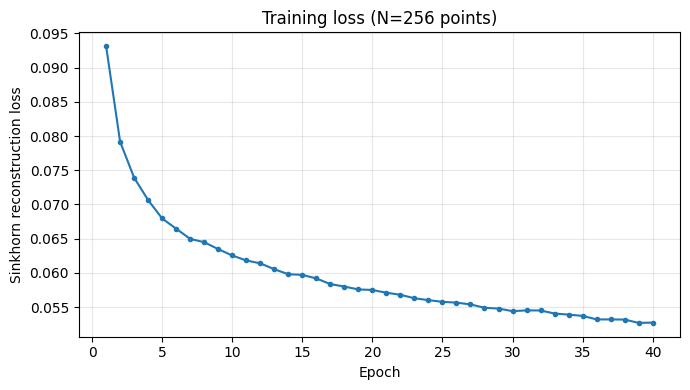

In [22]:
# ============================================================
# CELL 5: Training loss curve
# ============================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(history) + 1), history, marker='o', markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Sinkhorn reconstruction loss')
plt.title(f'Training loss (N={config.num_points} points)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

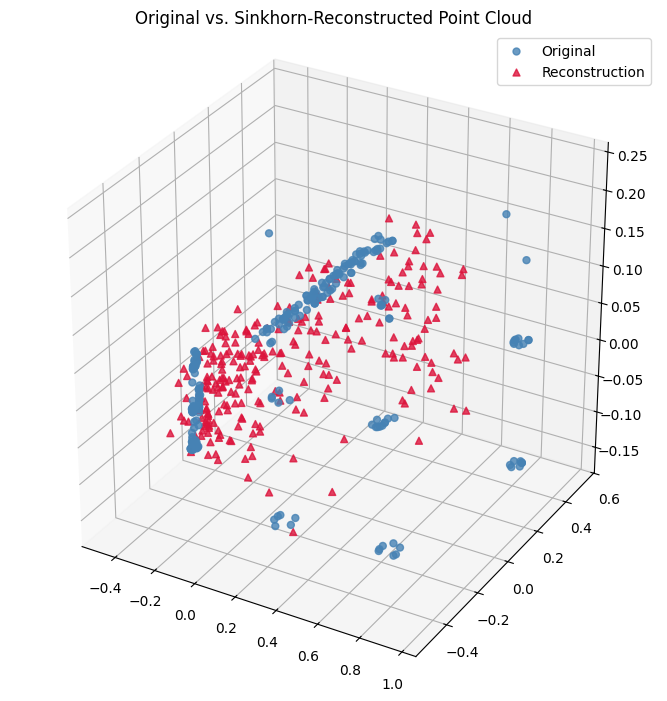

Sinkhorn cost for this sample: 0.0599


In [23]:
# ============================================================
# CELL 6: 3D scatter overlay — original vs. reconstructed
# ============================================================
model.eval()
with torch.no_grad():
    xb = next(iter(test_loader)).to(config.device)
    x_hat = model(xb)

idx = 0
orig = xb[idx].cpu().numpy()
recon = x_hat[idx].cpu().numpy()

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(orig[:, 0], orig[:, 1], orig[:, 2], s=25, c='steelblue',
           label='Original', alpha=0.8)
ax.scatter(recon[:, 0], recon[:, 1], recon[:, 2], s=25, c='crimson', marker='^',
           label='Reconstruction', alpha=0.8)
ax.set_title('Original vs. Sinkhorn-Reconstructed Point Cloud')
ax.set_box_aspect([1, 1, 1])
ax.legend()
plt.tight_layout()
plt.show()

sample_loss = sinkhorn_loss(xb[idx:idx+1], x_hat[idx:idx+1],
                             config.sinkhorn_epsilon, config.sinkhorn_iters)
print(f"Sinkhorn cost for this sample: {sample_loss.item():.4f}")

40 classes available, e.g.: ['airplane', 'bathtub', 'bed', 'bench', 'bookshelf', 'bottle', 'bowl', 'car', 'chair', 'cone']


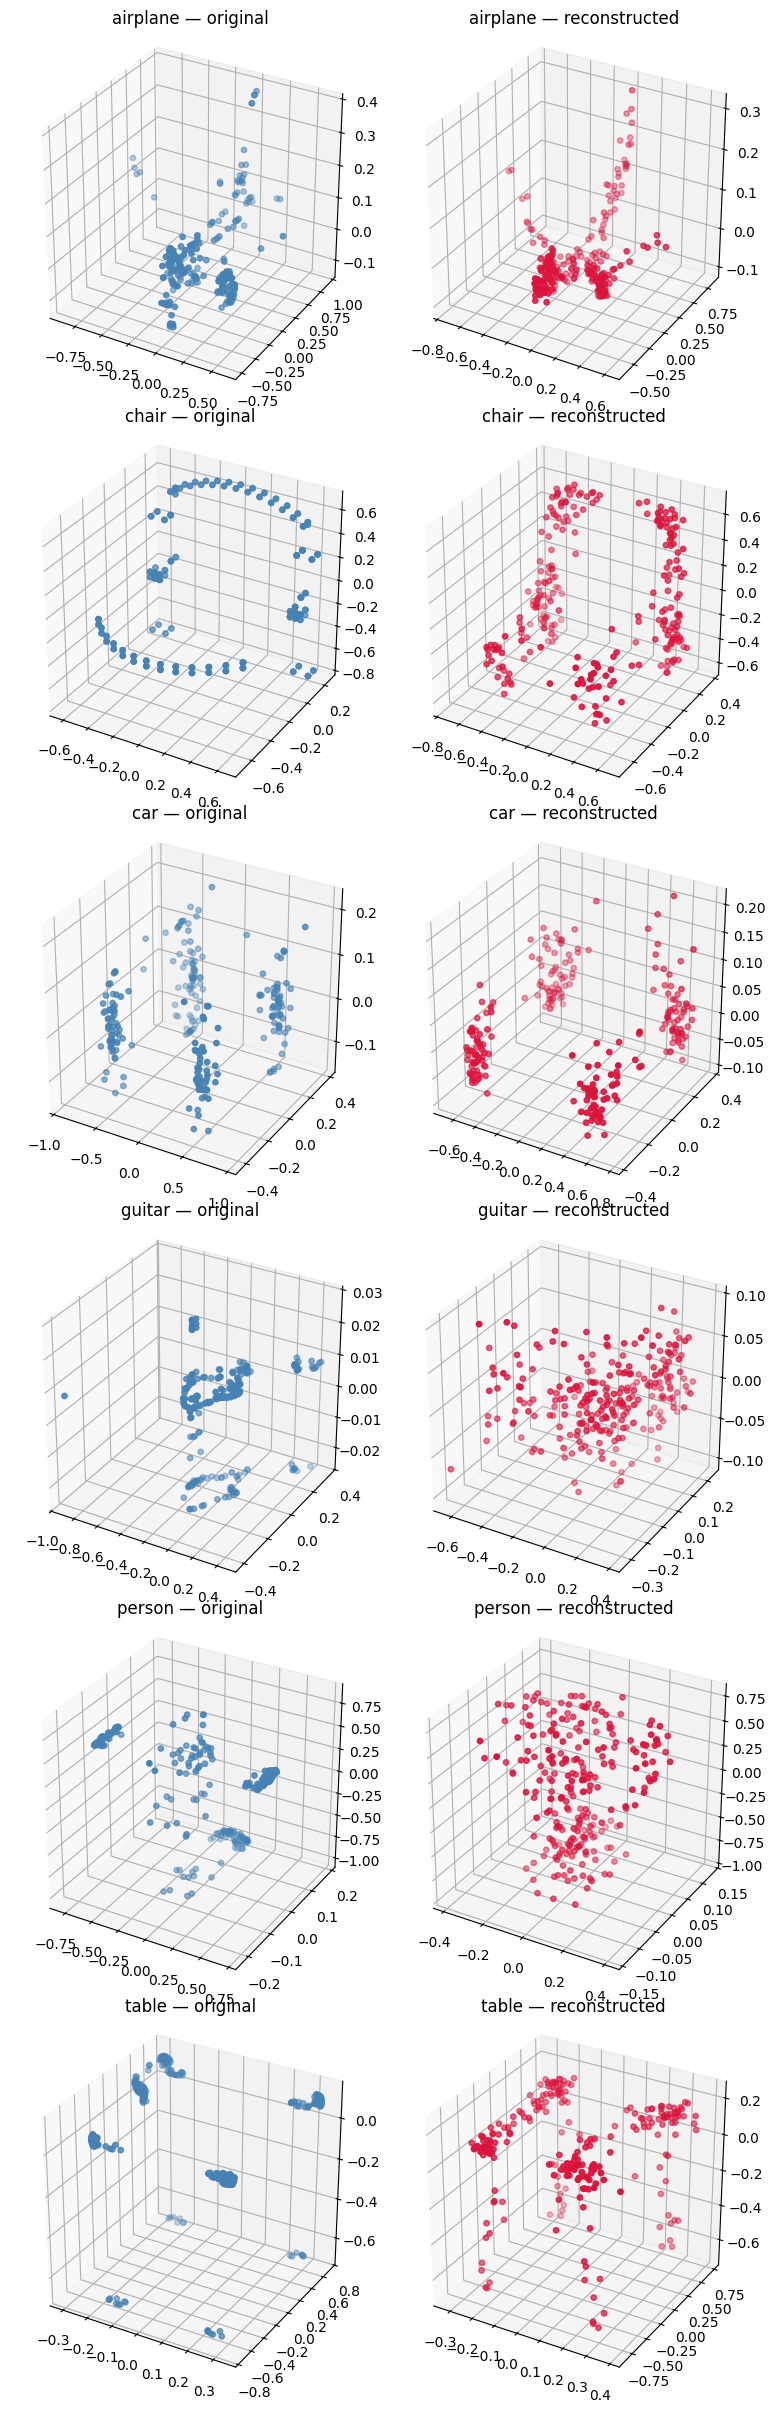

In [24]:
# ============================================================
# CELL 7: Per-class qualitative test — does airplane stay airplane?
# ============================================================
import glob

def load_single_pointcloud(filepath, num_points):
    verts = _cached_read_off(filepath)
    n = len(verts)
    sel = np.random.choice(n, num_points, replace=(n < num_points))
    pts = verts[sel]
    pts = pts - pts.mean(axis=0, keepdims=True)
    pts = pts / (np.linalg.norm(pts, axis=1).max() + 1e-6)
    return torch.from_numpy(pts.astype(np.float32))

available_classes = sorted(os.listdir(config.data_root))
print(f"{len(available_classes)} classes available, e.g.: {available_classes[:10]}")

# Pick a handful to eyeball -- edit this list to whatever classes you care about
test_classes = ['airplane', 'chair', 'car', 'guitar', 'person', 'table']
test_classes = [c for c in test_classes if c in available_classes]

model.eval()
fig, axes = plt.subplots(len(test_classes), 2, figsize=(8, 4 * len(test_classes)),
                          subplot_kw={'projection': '3d'})

for row, cls in enumerate(test_classes):
    files = glob.glob(os.path.join(config.data_root, cls, 'test', '*.off'))
    pts = load_single_pointcloud(files[0], config.num_points).unsqueeze(0).to(config.device)

    with torch.no_grad():
        recon = model(pts)

    orig_np = pts[0].cpu().numpy()
    recon_np = recon[0].cpu().numpy()

    axes[row, 0].scatter(orig_np[:, 0], orig_np[:, 1], orig_np[:, 2], s=15, c='steelblue')
    axes[row, 0].set_title(f'{cls} — original')
    axes[row, 1].scatter(recon_np[:, 0], recon_np[:, 1], recon_np[:, 2], s=15, c='crimson')
    axes[row, 1].set_title(f'{cls} — reconstructed')
    for ax in (axes[row, 0], axes[row, 1]):
        ax.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()